# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

# Aula 07 - Laboratório 2 - Alterações na taxa de amostragem e quantização de sinais de áudio e voz

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook e o arquivo, contendo os resultados e as respostas das questões, enviado em formato .ipynb pelo formulário.

Objetivos: Realizar alterações na taxa de amostragem e na quantização de sinais de áudio e voz e observar os seus efeitos

In [64]:
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

# Downsampling
def decimate(x, q):
    # Downsample the signal
    sl = [slice(None)] * x.ndim
    sl = slice(None, None, q)

    return x[sl]

# Upsampling
def upsample(x, p):
    # upsample the signal
    ylen = p*len(x)
    y    = np.zeros(ylen)
    sl = [slice(None)] * y.ndim
    sl = slice(None, None, p)
    y[sl] = x
    return y

#Plot frequency and phase response - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz(b,a=1):
    w,h = signal.freqz(b,a)
    h_dB = 20 * log10 (abs(h))
    plt.figure(figsize=(12,6))
    subplot(211)
    plot(w/max(w),abs(h))
    ylim(0, 1.5)
    ylabel('Amplitude')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(212)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)

def quantize(x, S):
    X = x.reshape((-1,1))
    S = S.reshape((1,-1))
    dists = abs(X-S)

    nearestIndex = dists.argmin(axis=1)
    quantized = S.flat[nearestIndex]

    return quantized.reshape(x.shape)

In [65]:
import os, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/Mathcd/2026-3-Processamento-de-Voz-e-Audio/main/2-ExerciciosComputacionais/Audios/"

def caminho_audio(nome):
    """Usa o áudio local se existir; senão baixa do GitHub (ex.: no Colab)."""
    caminho = os.path.join("Audios", nome)
    if not os.path.exists(caminho):
        os.makedirs("Audios", exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + nome, caminho)
    return caminho

# Abrindo e escutando um sinal de áudio

In [66]:
audio_sample, fs = librosa.load(caminho_audio("audio.wav"), sr=48000)

Nos primeiros 3 segundos do arquivo "audio.wav" é possível escutar um sinal de **voz** da letra "u" sendo repetido. No intervalo de 3 a 6 segundos é possível escutar um **violino** sendo tocado. No intervalo de 6 a 9 segundos é possível escutar uma **chave** chacoalhando e nos últimos três segundos do áudio é possível escutar os três sons simultaneamente.

In [67]:
Audio(data=audio_sample, rate=fs)

## Pergunta 1 - Foi possível escutar todos os sons?

Sim, foi possível escutar todos os sons. Em cada um dos intervalos de 3 segundos observa-se:

- No primeiro segmento há a voz de uma pessoa falando a vogal "u" de maneira sustentada; 
- No segundo é um violino tocando notas agudas; 
- No terceiro trata-se de um molho de chaves sendo chacoalhado;
- No quarto podemos ouvir os três áudios anteriores tocando simultaneamente. Como eles estão somados, não é possível ouvir com a mesma clareza com que os áudios que estão tocando individualmente, mas ainda assim é possível notar a presença dos três sinais tocando ao mesmo tempo.

# Visualizando a forma de onda

Para visualizar a forma de onda do sinal de áudio pode-se utilizar o código abaixo.

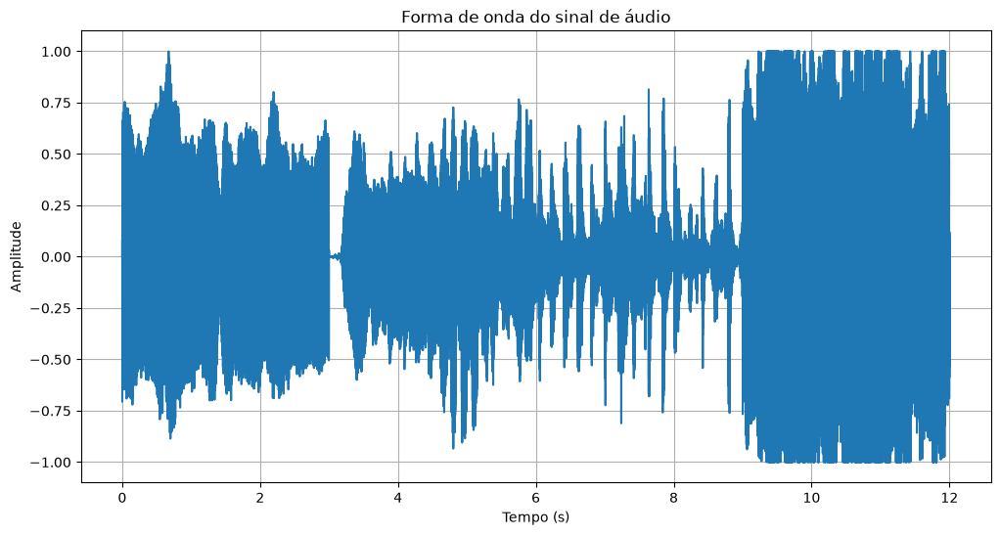

In [68]:
T  = len(audio_sample)/fs
t  = np.linspace(0,T,int(T*fs), endpoint=False)
plt.figure(figsize=(12,6))
plt.plot(t,audio_sample)
plt.title('Forma de onda do sinal de áudio')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.grid(True)

## Pergunta 2 - É possível diferenciar os diferentes sons através da sua forma de onda?

Sim! O primeiro trecho do áudio possui uma característica que o diferencia mais claramente dos outros dois: devido a amplitude e energia, a forma de onda compactada aparece mais "preenchida" e uniforme no intervalo analisado, considerando a escala do plot observado. No segundo já conseguimos observar a variação na amplitude do sinal, enquanto no terceiro essa variação é ainda mais acentuada. Por fim, no quarto segmento, devido a soma direta das amplitudes dos 3 primeiros sinais, observa-se a presença de "clipping", na qual a soma dos sinais ultrapassou os limites [-1, +1] do sistema, que limitou a saída nesses valores.

# Visualizando o espectro de amplitude

Para visualizar o espectro de amplitude do sinal na escala linear e em dB pode-se utilizar o código abaixo.

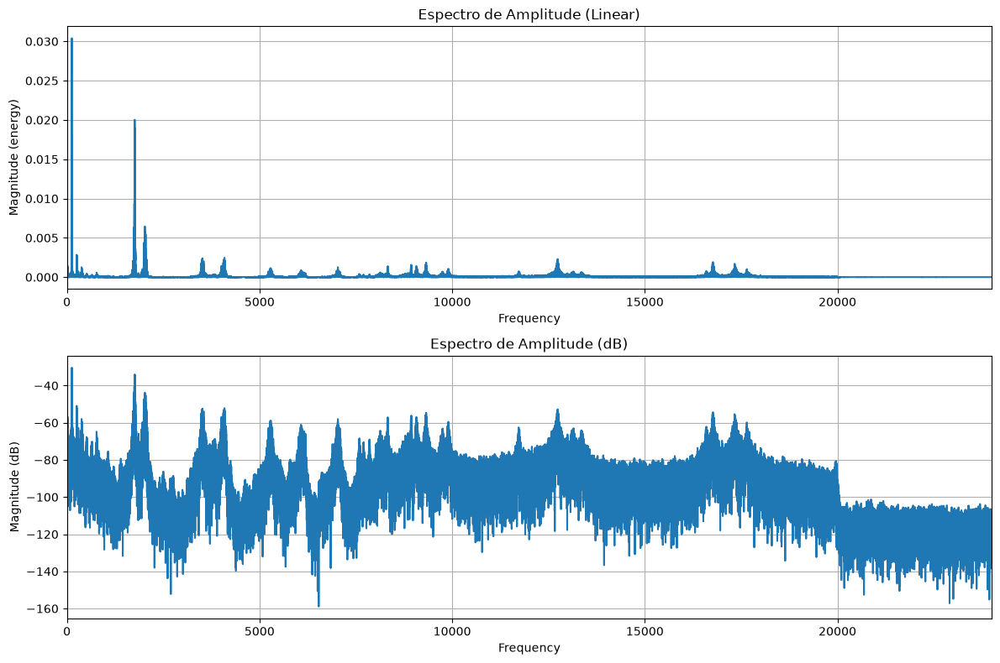

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8)) # Aumentei um pouco a altura para acomodar melhor os dois gráficos

# Primeiro gráfico (Escala Linear)
plt.subplot(2, 1, 1)
plt.magnitude_spectrum(audio_sample, Fs=fs)
plt.title('Espectro de Amplitude (Linear)') # Título específico para o subplot 1
plt.grid(True)
plt.xlim([0, fs/2])

# Segundo gráfico (Escala em dB)
plt.subplot(2, 1, 2)
plt.magnitude_spectrum(audio_sample, Fs=fs, scale="dB")
plt.title('Espectro de Amplitude (dB)') # Título específico para o subplot 2
plt.grid(True)
plt.xlim([0, fs/2])

plt.tight_layout()

plt.show()


## Pergunta 3 - É possível diferenciar os diferentes sons através do espectro de amplitude? Para você, qual a melhor escala, linear (acima) ou dB (abaixo)?

Não. Ambas as representações mostram as componentes de frequência do áudio como um todo. Dessa forma, é possível identificar quais componentes de frequência estão presentes no áudio e suas respectivas magnitudes, mas não sendo possível diferenciá-los. Já em relação à caracterização do áudio como um todo, a escala dB apresenta uma visualização melhor, pois ao adotarmos uma escala logarítmica para representar as amplitudes, componentes que possuem energia significativamente mais baixas (como é o caso dos sons de alta frequência das chaves), que são de difícil visualização na escala linear, passam a aparecer mais claramente na escala dB, permitindo uma visualização e análise melhores. Além disso, tendo em vista que a nossa percepção de áudio é logarítmica, faz mais sentido a adoção dessa escala.

# Visualizando o espectrograma

Para visualizar o espectrograma do sinal pode-se utilizar o código abaixo.

Text(0, 0.5, 'Frequency [Hz]')

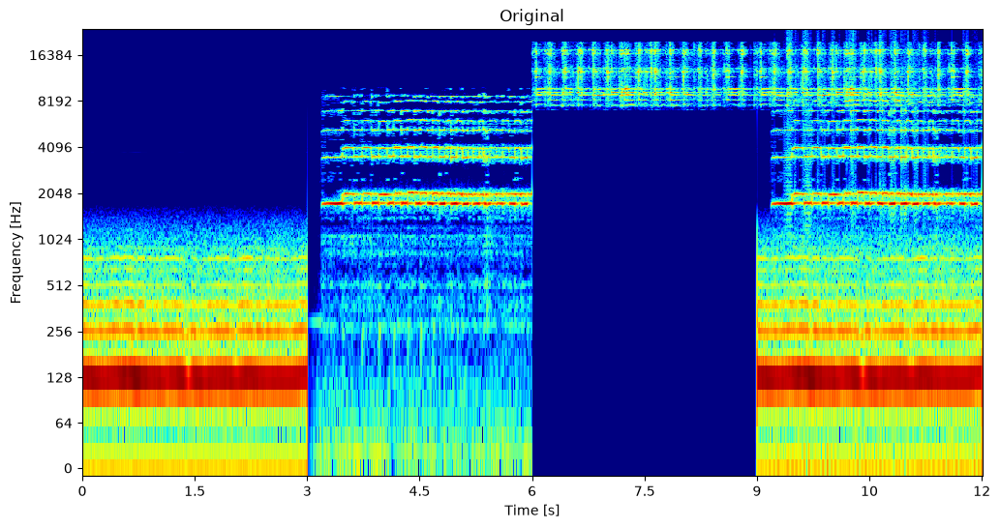

In [70]:
audio_stft = np.abs(librosa.stft(audio_sample))
plt.figure(figsize=(12,6))
specshow(librosa.amplitude_to_db(audio_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')

## Pergunta 4 - É possível diferenciar os diferentes sons através do espectrograma?

Sim! Tendo em vista que o espectrograma apresenta a informação de frequência do áudio ao longo do tempo, é possível identificar as componentes que caracterizam cada um dos segmentos. No primeiro segmento, observa-se uma componente de alta energia em aproximadamente 128 Hz, que é o padrão grave observado ao ouvir o áudio, bem como as componentes harmônicas em 256 Hz, 384 Hz, 512 Hz, etc.

Já o segundo segmento é caracterizado por componentes de alta energia nas frequências de aproximadamente 1750 e 2000 Hz, associadas às notas/acordes que estão sendo tocados pelo instrumento; de maneira análoga, também podemos observar as harmônicas nos múltiplos da frequência base, tal como 3500-4000 Hz. Apesar de essas serem as componentes de frequêcia que se destacam, todo o espectro inferior possui outras componentes que "preenchem" o sinal.

O terceiro segmento se destaca dos dois anteriores por conter exclusivamente componentes de alta frequência. Pelo espectrograma, pode-se observar que praticamente não há componentes de frequência menores que 8000 Hz, o que caracteriza esse segmento.

Por fim, no quarto segmento, que constitui a soma dos três anteriores no tempo, também podemos observar que o espectrograma resultante equivale à soma dos anteriores. Além disso, observa que nessa soma estão presentes componentes com a frequência ainda mais alta que as componentes mais altas de cada um dos outros segmentos. Isso se deve possivelmente a artefatos resultantes da saturação causada pela soma das formas de onda sem a devida normalização (por exemplo multiplicando por 1/3).

Com base nisso, visualmente é possivel diferenciar esses segmentos, e até mesmo treinar um classificador capaz de discriminá-los


## Pergunta 5 - Para você, qual ferramenta foi melhor para visualizar os diferentes sons? A forma de onda, o espectro de amplitude ou o espectrograma?

O espectrograma foi o melhor. A forma de onda dá uma noção de caracterização do sinal, mas é ligeiramente difícil de distinguir os áudios 2 e 3, por exemplo, embora a representação temporal ajude a identificar os trechos conforme se escuta. No espectro de amplitude, apesar de ser possível identificar as componentes de frequências, elas estão todas sobrepostas, não sendo possível tirar conclusões a respeito das diferentes características de cada áudio, já que o espectro sobrepõe o áudio inteiro como uma representação única. O espectrograma, em contrapartida, combina o melhor dos dois cenários: apresenta uma representação temporal, que permite identificar os trechos de início e fim de cada áudio, e a representação de amplitude em cada frequência, de modo a permitir a caracterização de cada segmento de áudio, conforme foi observado.

# Reamostrando o sinal de áudio, com e sem filtro anti-aliasing

Vamos definir as seguintes variáveis para armazenar os sinais de áudio:
* s  - sinal de áudio original, com frequência de amostragem fs = 48000
* sr - sinal de áudio reamostrado sem filtro, com frequência de amostragem igual a fs/q, onde q é o fator de decimação;
* x  - sinal de áudio original filtrado, com frequência de amostragem igual a fs = 48000
* xr - sinal de áudio com filtro anti-aliasing reamostrado, com frequência de amostragem igual a fs/q, onde q é o fator de decimação;

Para um fator de decimação q, vamos definir um filtro anti-aliasing com frequência angular $\omega = \pi/q$ e ordem igual a $40*q$. Neste primeiro caso, iremos utilizar um fator de decimação igual a 2.

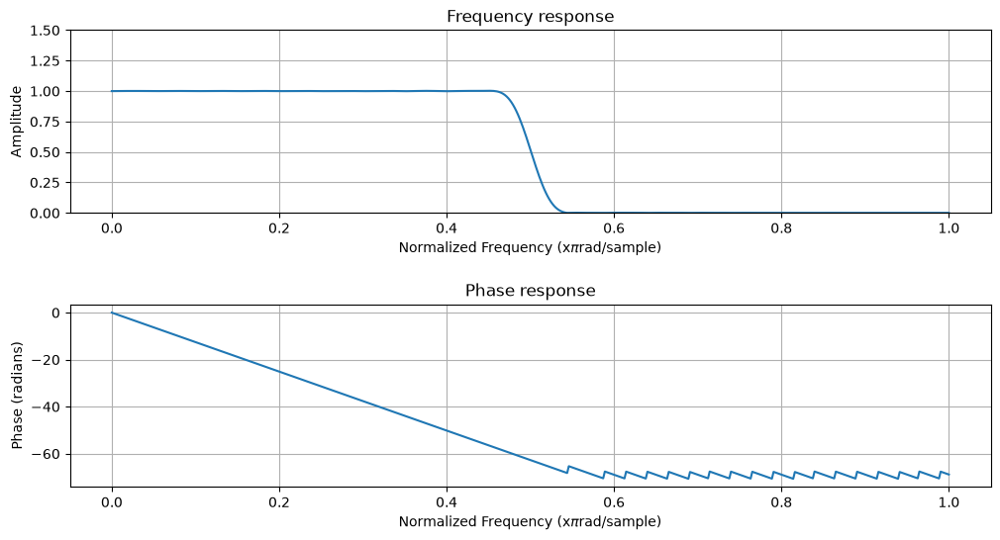

In [71]:
q   = 2; # Fator de decimação
fpb = signal.firwin(40*q+1, cutoff = 1/(q), window = "hamming") # cutoff

#Frequency and phase response
mfreqz(fpb)

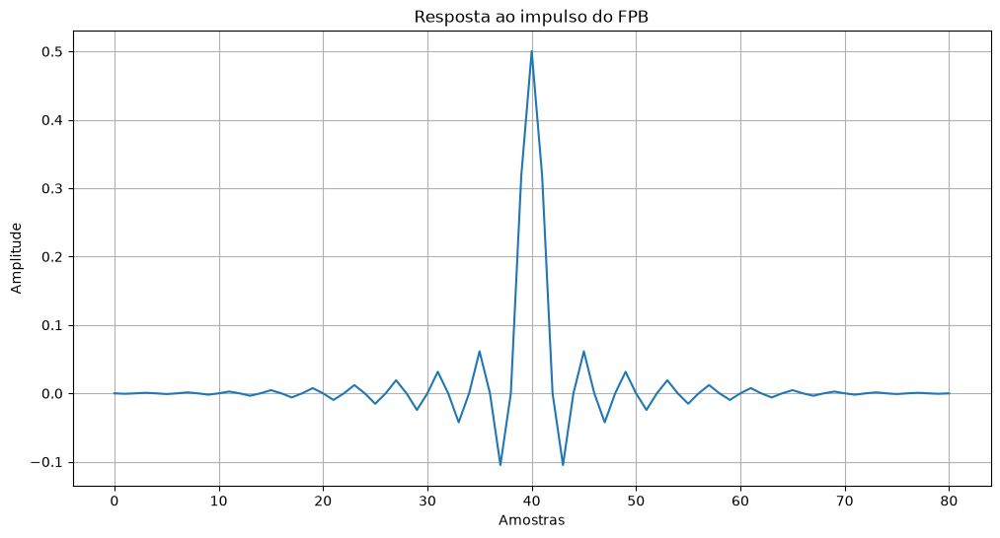

In [72]:
plt.figure(figsize=(12,6))
plt.plot(fpb)
plt.title('Resposta ao impulso do FPB')
plt.xlabel('Amostras')
plt.ylabel('Amplitude')
plt.grid(True)

In [73]:
s  = audio_sample
x  = np.convolve(fpb,s,'same')
sr = decimate(s,q)
xr = decimate(x,q)
tr = np.linspace(0,len(xr),len(xr), endpoint=False)
fr = fs/q
tr = tr/fr
Audio(data=s, rate=fs) # Audio original

In [74]:
Audio(data=sr, rate=fr) # Audio reamostrado sem filtro anti-aliasing


In [75]:
Audio(data=x, rate=fs) # Audio filtrado com filtro anti-aliasing

In [76]:
Audio(data=xr, rate=fr) # Audio reamostrado pré-processado com filtro anti-aliasing

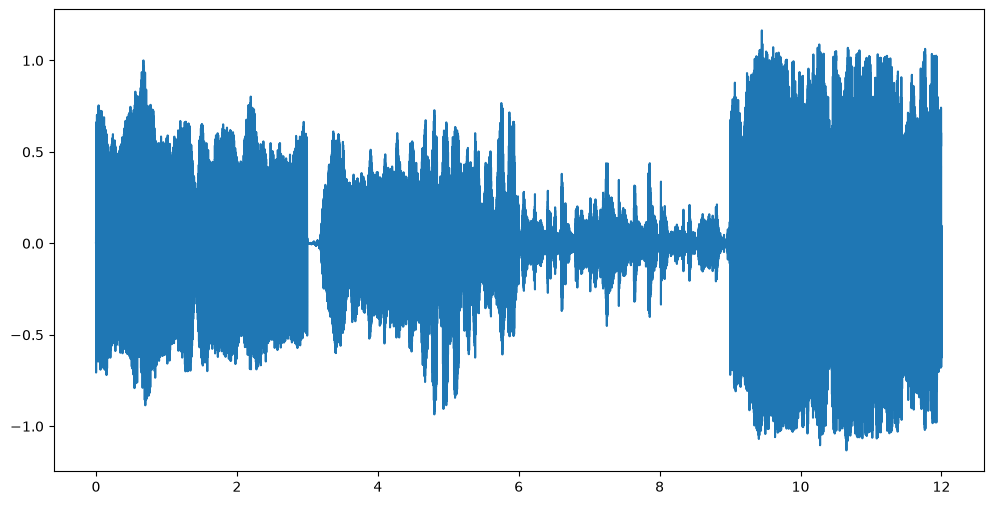

In [77]:
plt.figure(figsize=(12,6))
plt.plot(t,x)

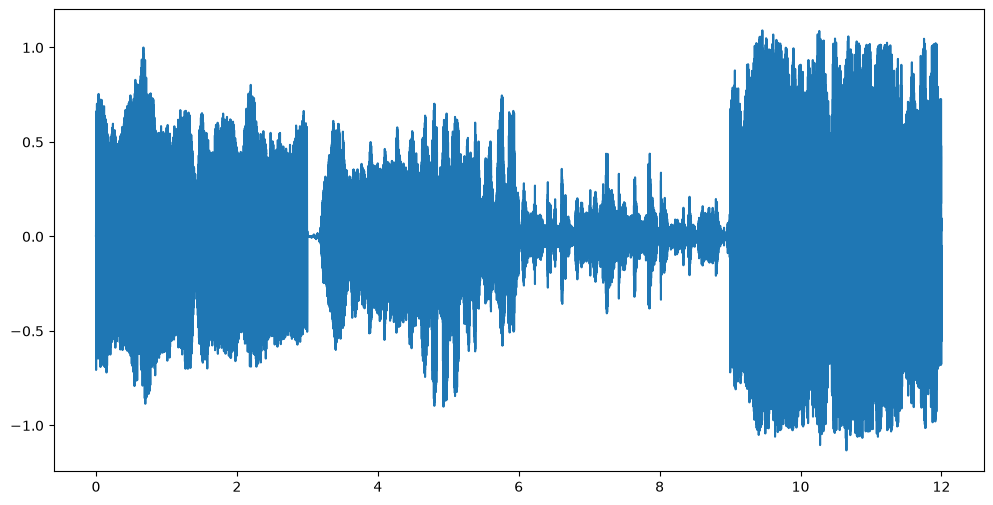

In [78]:
plt.figure(figsize=(12,6))
plt.plot(tr,xr)

## Pergunta 6 - É possível perceber alguma diferença entre os sons de s (original) e de sr (reamostrado)?

Sim, mas apenas em parte do áudio. No primeiro e segundo segmentos praticamente não é possível perceber diferença, já que todas as componentes desses sons estão abaixo da nova frequência de Nyquist (24/2 = 12 kHz). Já no terceiro segmento o som ficou claramente diferente, inclusive até parece ser outro objeto que está sendo chacoalhado (por exemplo latas ou tampinhas de garrafa de vidro). Isso ocorre pelo efeito de aliasing, no qual as componentes de alta frequência (acima de 12 kHz), após a reamostragem, são rebatidas para a faixas mais baixas, o que configura um tipo de distorção. Esse efeito também pode ser observado no quarto segmento, porém de maneira menos acentuada, já que ao tocar todos os sons simultaneamente, os dois primeiros acabam mascarando parcialmente a percepção da distorção do terceiro.

## Pergunta 7 - É possível perceber alguma diferença entre os sons de s (original) e de x (filtrado)?


Sim, novamente apenas no terceiro segmento (e no quarto, de maneira mais sutil). O filtro passa-baixas usado tem frequência de corte em 12 kHz, e portanto remove as componentes acima dessa frequência. Nesse caso, o som fica mais parecido com o original (em relação ao sr), porém um pouco mais abafado, como se tivesse perdido parte do "brilho" que o áudio original possui (resultado das componentes de alta frequência que foram cortadas).

## Pergunta 8 - É possível perceber alguma diferença entre os sons de x (filtrado) e de xr (filtrado e reamostrado)?

Pela análise gráfica (plots abaixo) observa-se que os espectrogramas dos sinais filtrado e filtrado+reamostrado são muito parecidos nas faixas de frequências médias e altas, e com uma ligeira diferença nas componentes de baixa frequência, o que possivelmente ocorre por uma diferença no plot dos espectrogramas: x está em 48 kHz e xr em 24 kHz, mas ambos usam a mesma janela de 2048 amostras. Perceptualmente, ambos os áudios são muito semelhantes, de modo que não foi possível observar uma diferença clara audível entre ambos.

(0.0, 24000.0)

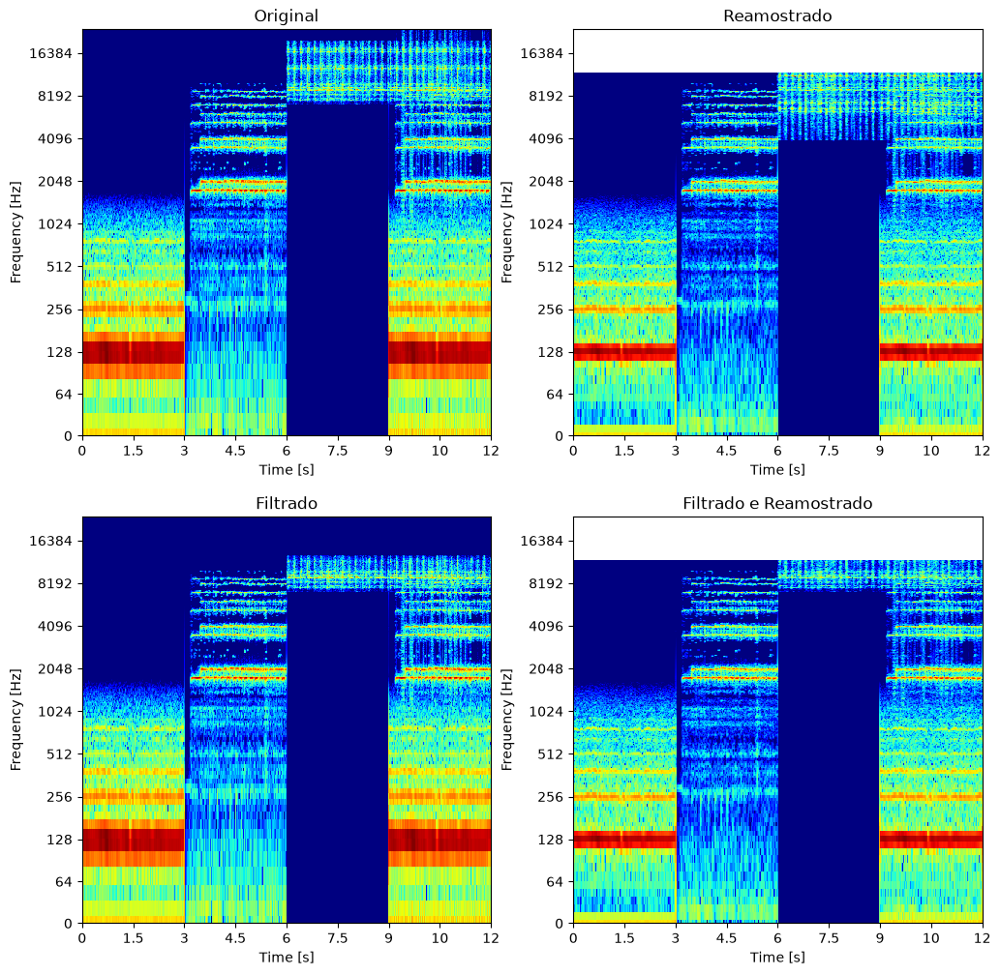

In [79]:
s_stft = np.abs(librosa.stft(s))
x_stft = np.abs(librosa.stft(x))
sr_stft = np.abs(librosa.stft(sr))
xr_stft = np.abs(librosa.stft(xr))
plt.figure(figsize=(12,12))
plt.subplot(2,2,1)
specshow(librosa.amplitude_to_db(s_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

plt.subplot(2,2,3)
specshow(librosa.amplitude_to_db(x_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Filtrado')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

plt.subplot(2,2,2)
specshow(librosa.amplitude_to_db(sr_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fr)
plt.title('Reamostrado')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

plt.subplot(2,2,4)
specshow(librosa.amplitude_to_db(xr_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fr)
plt.title('Filtrado e Reamostrado')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

## Pergunta 9 - Analisando os espectrogramas, é possível perceber o efeito de alising? Se sim, qual som ou sons (voz, violino e/ou chave) são os mais afetados?


Sim! Observando o espectrograma, é possível observar que o áudio reamostrado possui uma série de distorções inseridas nas componentes que sobraram no espectro após a reamostragem, em especial no áudio do terceiro segmento (chaves), que é exclusivamente composto por componentes de alta frequência (acima de 12 kHz). Isso se deve ao rebatimento das altas frequências quando o áudio é reamostrado. E esse efeito fica ainda mais agravante quando se utiliza q=4 ou q=6. Além disso, também é possível perceber que nos sinais reamostrados não há componentes acima de 12 kHz, pois esta é a frequência máxima que pode ser representada em 24 kHz.

## Repita os exercícios relativos às perguntas 6, 7, 8, e 9 considerando q = 4 e q = 6.

In [80]:
from IPython.display import display

In [81]:
def plot_espectrogramas(s, x, sr, xr, fs, fr, q):
    """Espectrogramas do sinal original, reamostrado, filtrado e filtrado+reamostrado."""
    sinais = [(s,  fs, 'Original'),
              (sr, fr, f'Reamostrado (q={q}, fs={fr:.0f} Hz)'),
              (x,  fs, f'Filtrado (corte em {fs/(2*q):.0f} Hz)'),
              (xr, fr, f'Filtrado e Reamostrado (q={q}, fs={fr:.0f} Hz)')]
    plt.figure(figsize=(12,12))
    for i, (sinal, taxa, titulo) in enumerate(sinais):
        plt.subplot(2, 2, i+1)
        specshow(librosa.amplitude_to_db(np.abs(librosa.stft(sinal))),
                 y_axis='log',
                 x_axis='time',
                 cmap='jet',
                 sr=taxa)
        plt.title(titulo)
        plt.xlabel('Time [s]')
        plt.ylabel('Frequency [Hz]')
        plt.ylim(0, fs/2)
    plt.tight_layout()
    plt.show()

In [82]:
q   = 4; # Fator de decimação
fpb = signal.firwin(40*q+1, cutoff = 1/(q), window = "hamming") # cutoff

s  = audio_sample
x  = np.convolve(fpb,s,'same')
sr = decimate(s,q)
xr = decimate(x,q)
tr = np.linspace(0,len(xr),len(xr), endpoint=False)
fr = fs/q
tr = tr/fr

display(Audio(data=s, rate=fs))  # Audio original
display(Audio(data=sr, rate=fr)) # Audio reamostrado sem filtro anti-aliasing
display(Audio(data=x, rate=fs))  # Audio filtrado com filtro anti-aliasing
display(Audio(data=xr, rate=fr)) # Audio reamostrado pré-processado com filtro anti-aliasing

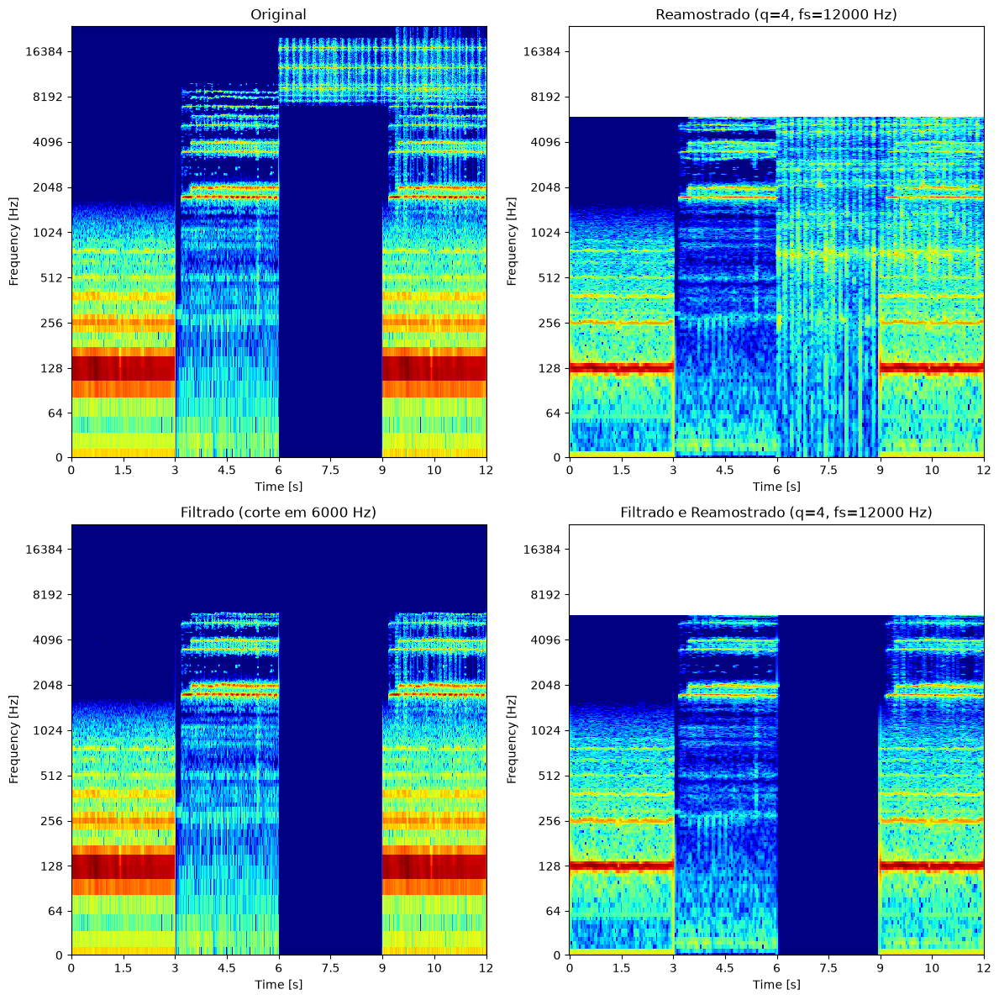

In [83]:
plot_espectrogramas(s, x, sr, xr, fs, fr, q)

In [84]:
q   = 6; # Fator de decimação
fpb = signal.firwin(40*q+1, cutoff = 1/(q), window = "hamming") # cutoff

s  = audio_sample
x  = np.convolve(fpb,s,'same')
sr = decimate(s,q)
xr = decimate(x,q)
tr = np.linspace(0,len(xr),len(xr), endpoint=False)
fr = fs/q
tr = tr/fr

display(Audio(data=s, rate=fs))  # Audio original
display(Audio(data=sr, rate=fr)) # Audio reamostrado sem filtro anti-aliasing
display(Audio(data=x, rate=fs))  # Audio filtrado com filtro anti-aliasing
display(Audio(data=xr, rate=fr)) # Audio reamostrado pré-processado com filtro anti-aliasing

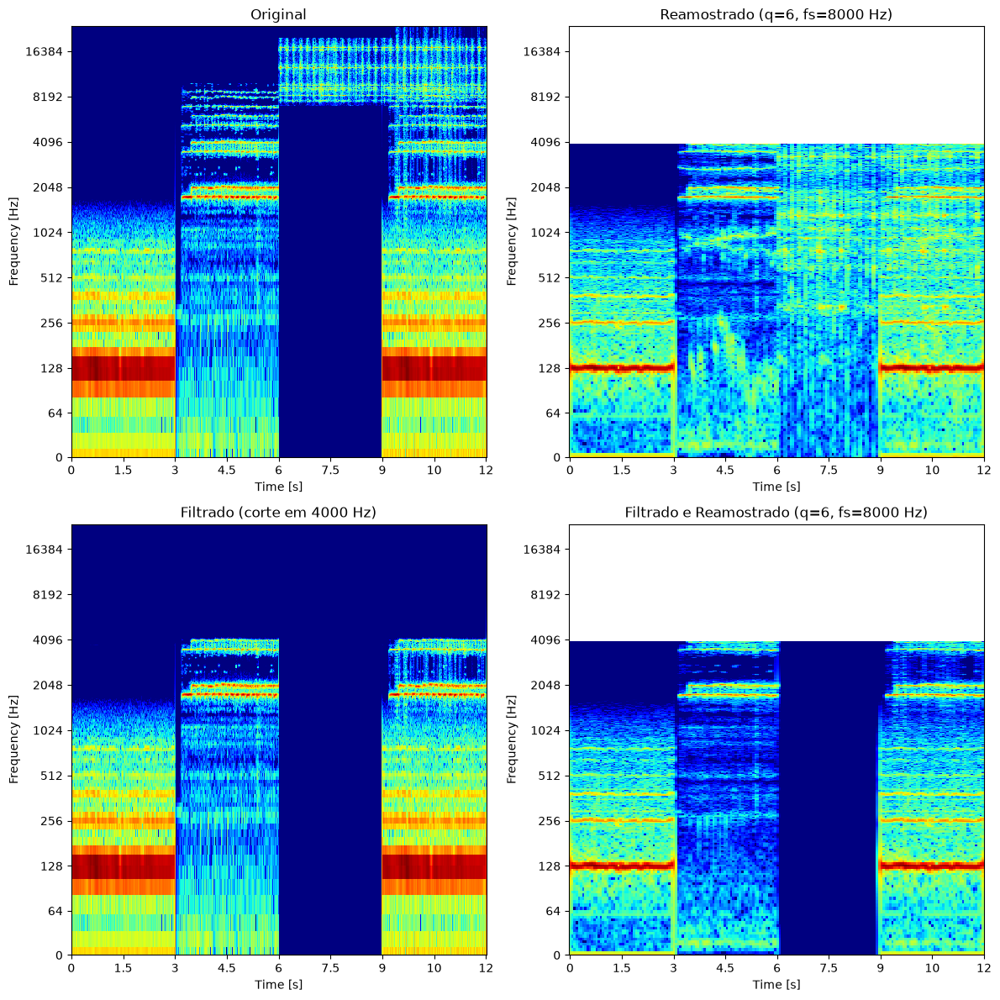

In [85]:
plot_espectrogramas(s, x, sr, xr, fs, fr, q)

# Requantizando o sinal de áudio

Para quantizar/requantizar um sinal de áudio é necessário definir o quantizador que será utilizado, o número de bits $b$ que será utilizado na codificação e a amplitude máxima do valor absoluto do sinal $U$ que será quantizado.

Neste exemplo, será utilizado um quantizador do tipo Mid-rise, com $U=1$ e iremos variar o número de bits que será utilizado na quantização. O áudio utilizado neste laboratório foi quantizado originalmente com 16bits.

Vamos definir as seguintes variáveis para armazenar os sinais de áudio:
* s  - sinal de áudio original;
* sq - sinal de áudio requantizado

Primeiramente, vamos requantizar este sinal com 8 bits.

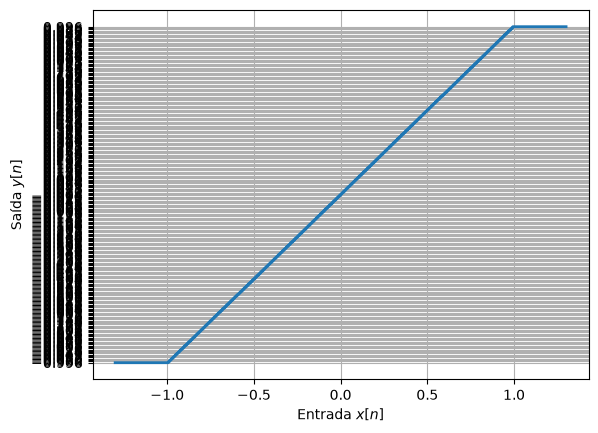

In [86]:
b = 8            # número de bits que será utilizado na quantização
U = 1            # amplitude máxima do sinal que será quantizado
L = 2**b         # número de níveis(intervalo) que será  utilizado na quantização
Delta_s   = 2*U/L  # passo de quantização
S_midrise = -U + Delta_s/2 + np.arange(L)*Delta_s # calcula os intervalos de quantização
#S_midtread = -U + np.arange(L)*Delta_s # calcula os intervalos de quantização
sq = quantize(s, S_midrise)
#sq = quantize(s, S_midtread)
e  = sq-s

In          = np.linspace(-1.3*U, 1.3*U, 2000)
Out_midrise = quantize(In, S_midrise)
plt.plot(In, Out_midrise, lw=2, label='mid-rise');
plt.xlabel('Entrada $x[n]$')
plt.ylabel('Saída $y[n]$')
plt.grid(True)
plt.yticks(S_midrise);

(10.0, 10.005)

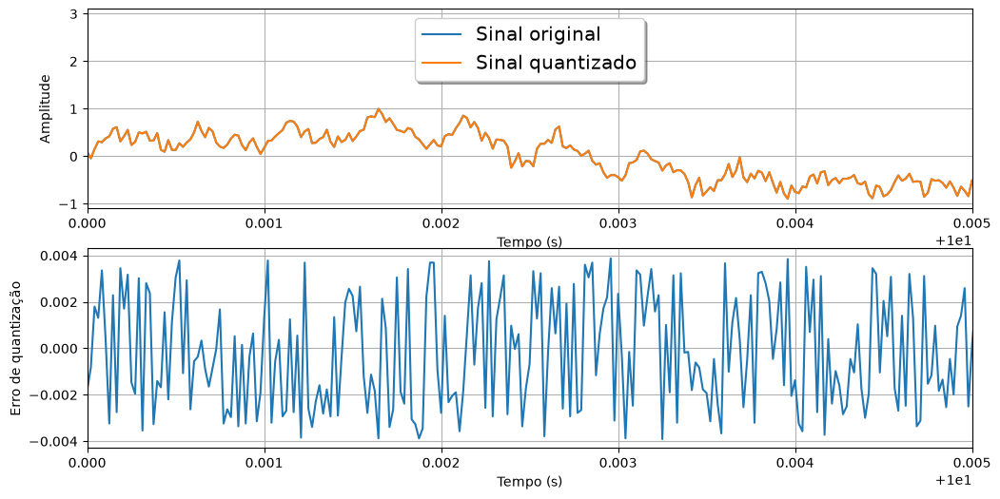

In [87]:
plt.figure(figsize=(12,6))
plt.subplot(2,1,1)
plt.plot(t,s,label='Sinal original')
plt.plot(t,sq,label='Sinal quantizado')
legend(loc='upper center', shadow=True, fontsize='x-large');
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.grid(True)
axes = plt.gca()
axes.set_ylim([-1.1,3.1])
axes.set_xlim([10,10.005])
plt.subplot(2,1,2)
plt.plot(t,e)
plt.xlabel('Tempo (s)')
plt.ylabel('Erro de quantização')
plt.grid(True)
axes = plt.gca()
axes.set_xlim([10,10.005])

In [88]:
Audio(data=s, rate=fs)

In [89]:
Audio(data=sq, rate=fs)

In [90]:
Audio(data=e, rate=fs)

(0.0, 24000.0)

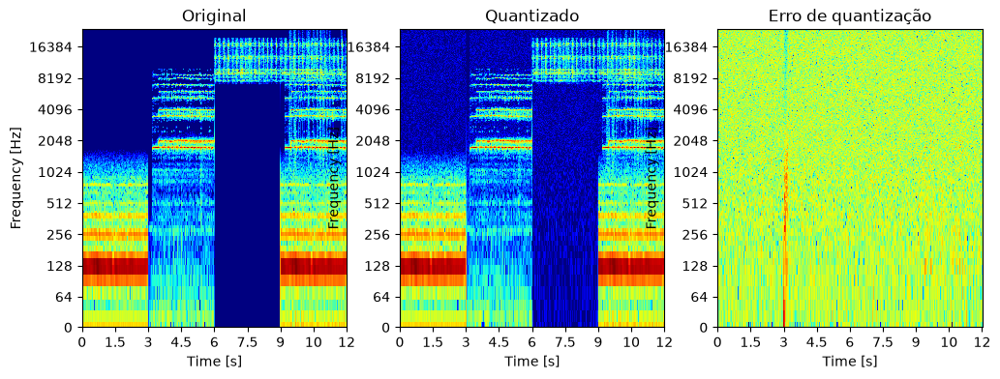

In [91]:
s_stft = np.abs(librosa.stft(s))
sq_stft = np.abs(librosa.stft(sq))
e_stft = np.abs(librosa.stft(e))
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
specshow(librosa.amplitude_to_db(s_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

plt.subplot(1,3,2)
specshow(librosa.amplitude_to_db(sq_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Quantizado')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

plt.subplot(1,3,3)
specshow(librosa.amplitude_to_db(e_stft),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Erro de quantização')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.ylim(0, fs/2)

# Pergunta 10 - Após a quantização, é possível perceber alguma difereça nos áudios? Se sim, qual ou quais áudios? É possível notar alguma diferença nos espectogramas?

Sim. Ouvindo os áudios, nota-se a presença de um leve (e sutil) chiado que acompanha todos os segmentos, especialmente os 3 primeiros (no quarto, como há vários sons tocando simultaneamente, é mais difícil de identificar). Pela análise gráfica é possível confirmar essa percepção, pois observa que todos os trechos que estavam em azul escuro (amplitude próxima de zero) passaram a ser preenchidos com um ruído, que é justamente o erro de quantização. Esse ruído também está presente no restante do espectro, embora não seja possível visualizá-lo diretamente.

## Repita os exercícios relativos à pergunta 10 considerando b = 4 e b = 2.

In [92]:
def requantizar(s, b, fs, U=1, zooms=(10, 7)):
    """Requantiza s com b bits (mid-rise), plota sinal/erro, toca os áudios e mostra os espectrogramas."""
    L = 2**b                                           # número de níveis
    Delta_s = 2*U/L                                    # passo de quantização
    S_midrise = -U + Delta_s/2 + np.arange(L)*Delta_s  # níveis de quantização
    sq = quantize(s, S_midrise)
    e  = sq - s
    t  = np.arange(len(s))/fs

    snr = 10*np.log10(np.sum(s**2)/np.sum(e**2))
    print(f'b = {b} bits | L = {L} níveis | Delta = {Delta_s:.5f} | SNR = {snr:.1f} dB')

    # Curva característica do quantizador
    In = np.linspace(-1.3*U, 1.3*U, 2000)
    plt.figure(figsize=(6,4))
    plt.plot(In, quantize(In, S_midrise), lw=2, label='mid-rise')
    plt.title(f'Quantizador mid-rise com {b} bits')
    plt.xlabel('Entrada $x[n]$')
    plt.ylabel('Saída $y[n]$')
    plt.grid(True)
    if L <= 16:
        plt.yticks(S_midrise)
    plt.show()

    # Sinal original x quantizado e erro, em janelas de 5 ms
    for t0 in zooms:
        plt.figure(figsize=(12,6))
        plt.subplot(2,1,1)
        plt.plot(t, s, label='Sinal original')
        plt.plot(t, sq, label='Sinal quantizado')
        plt.legend(loc='upper center', shadow=True, fontsize='x-large')
        plt.title(f'b = {b} bits - trecho de {t0} s a {t0+0.005} s')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.xlim([t0, t0+0.005])
        plt.subplot(2,1,2)
        plt.plot(t, e)
        plt.xlabel('Tempo (s)')
        plt.ylabel('Erro de quantização')
        plt.grid(True)
        plt.xlim([t0, t0+0.005])
        plt.show()

    # Áudios
    print('Original:');   display(Audio(data=s,  rate=fs))
    print('Quantizado:'); display(Audio(data=sq, rate=fs))
    print('Erro:');       display(Audio(data=e,  rate=fs))

    # Espectrogramas
    plt.figure(figsize=(12,4))
    for i, (sinal, titulo) in enumerate([(s, 'Original'), (sq, f'Quantizado ({b} bits)'), (e, 'Erro de quantização')]):
        plt.subplot(1,3,i+1)
        specshow(librosa.amplitude_to_db(np.abs(librosa.stft(sinal))),
                 y_axis='log',
                 x_axis='time',
                 cmap='jet',
                 sr=fs)
        plt.title(titulo)
        plt.xlabel('Time [s]')
        plt.ylabel('Frequency [Hz]')
        plt.ylim(0, fs/2)
    plt.tight_layout()
    plt.show()

    return sq, e

b = 4 bits | L = 16 níveis | Delta = 0.12500 | SNR = 18.6 dB


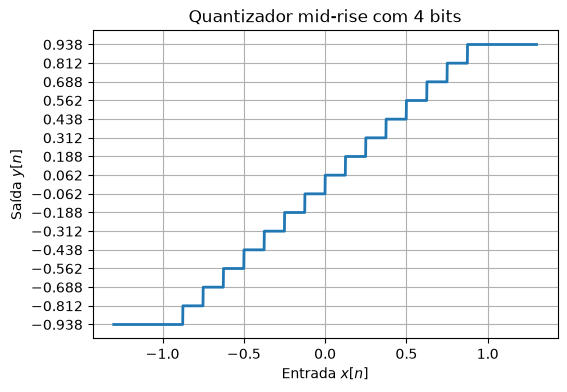

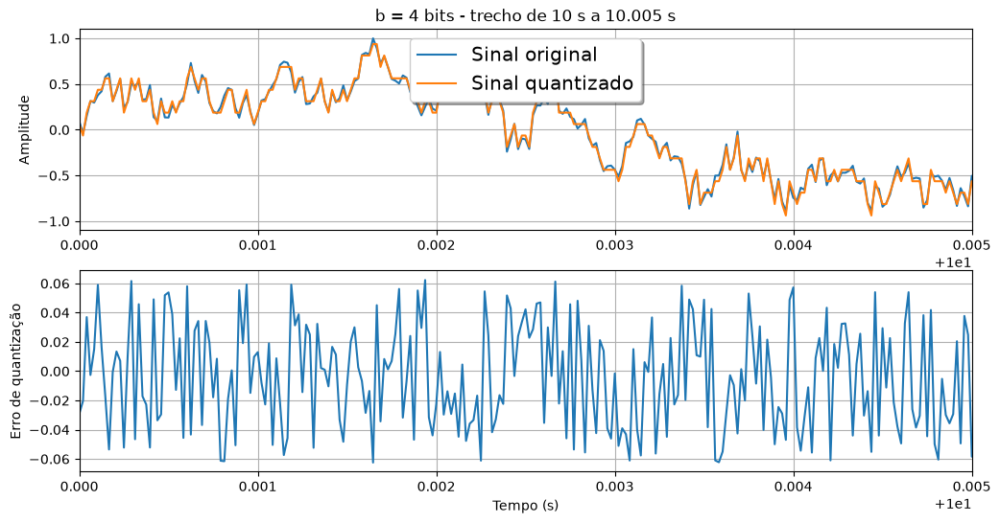

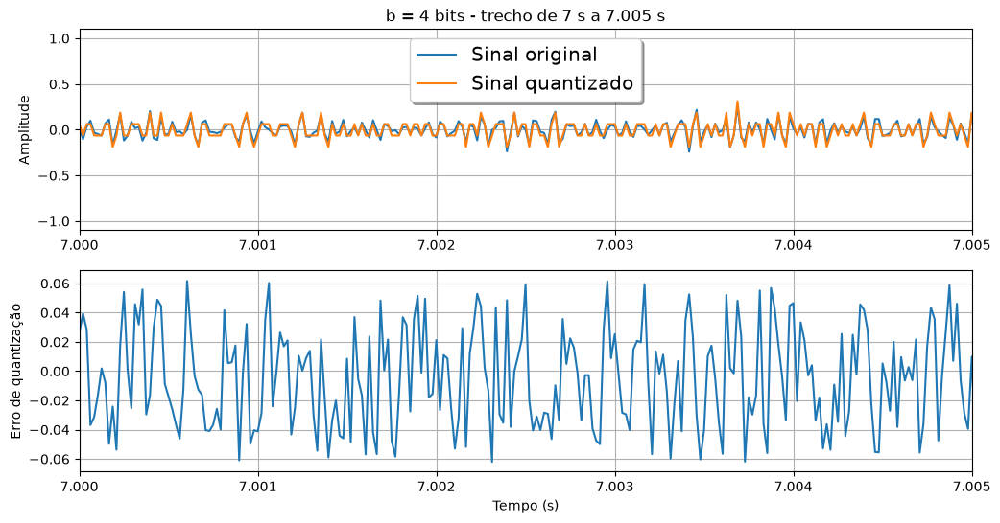

Original:


Quantizado:


Erro:


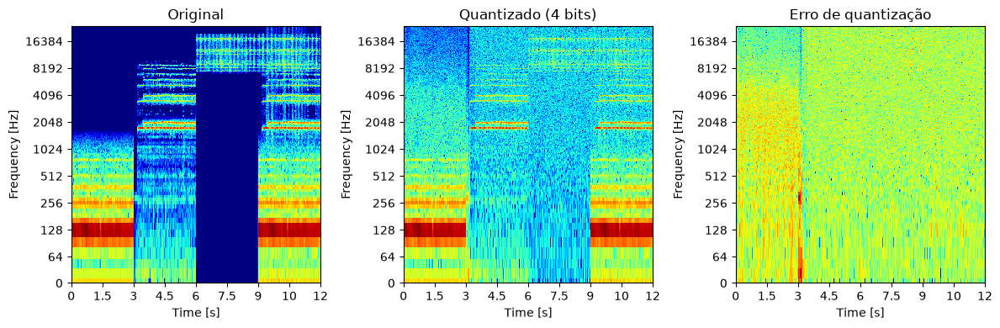

In [93]:
sq4, e4 = requantizar(s, 4, fs)

b = 2 bits | L = 4 níveis | Delta = 0.50000 | SNR = 5.6 dB


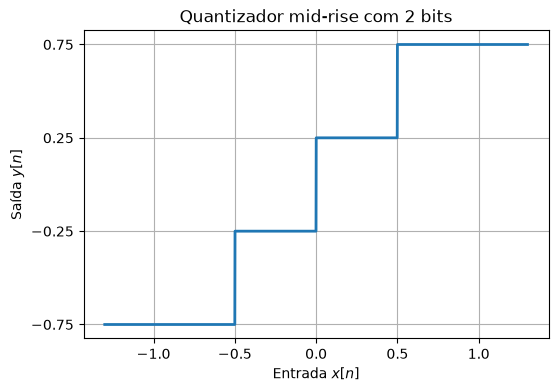

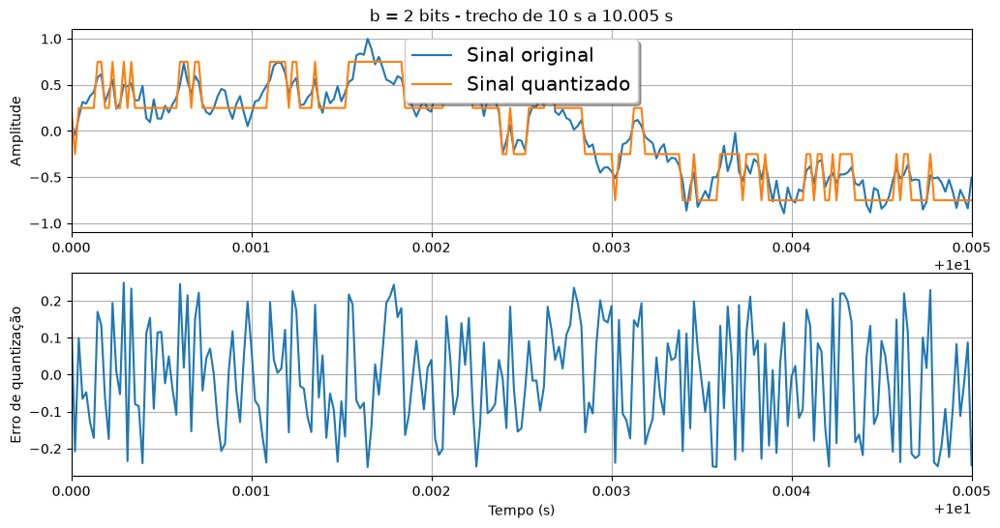

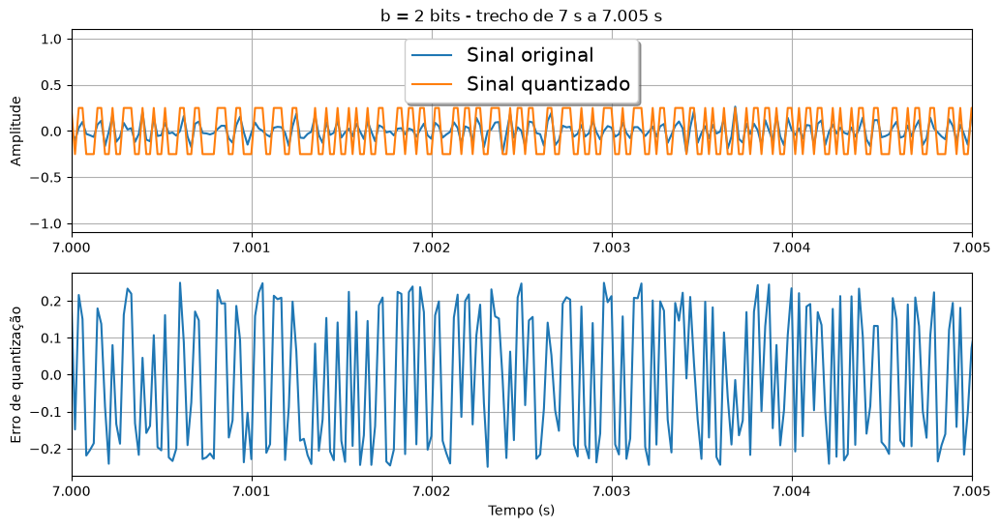

Original:


Quantizado:


Erro:


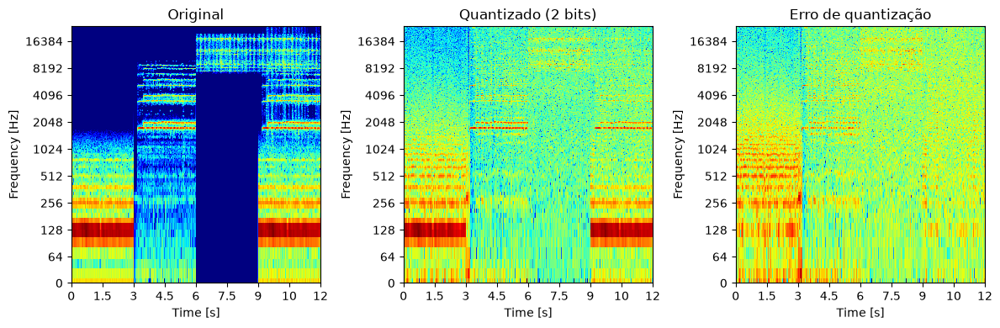

In [94]:
sq2, e2 = requantizar(s, 2, fs)

Com 4 bits a diferença deixa de ser sutil e o chiado passa a ser claramente perceptível. O espectrograma fica ainda mais ruidoso e os níveis de distorção inseridos passam a atrapalhar a compreensão dos sons, especialmente do terceiro segmento, que possui menor energia que os demais. Já com 2 bits é praticamente impossível interpretar os sons, pois o erro ficou tão alto que o próprio sinal ficou distorcido, como pode-se observar também no espectrograma.